# K-means 1 — geometric blobs and nearest-center assignment

**Goal:** see how a cloud of unlabeled 2D points becomes groups, implement the
assignment/update loop, and assign new points to the learned centers.
This is unsupervised clustering: the returned integers are group IDs.

**Prerequisites:** NumPy arrays and basic plotting. Run every cell in order.
Data are generated locally; no network access, external CSV, or GPU is needed.
Outputs are saved. Figures are also exported to `figures/` for the PDF.

We will keep simulated component labels hidden until after choosing K.
Both coordinates have the same units and noise scale, so we retain their geometry.

## 1. Imports and reproducibility
`KMeans.fit` learns centers; `predict` assigns rows to their nearest learned center. We fix seeds and explicitly request 20 starts rather than depend on version defaults.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEED = 23
COLORS = ["#147d92", "#e49b32", "#8b62a9", "#db6b59", "#3d9570", "#6b7494", "#ad6680", "#747c37"]
from matplotlib.colors import ListedColormap
CMAP = ListedColormap(COLORS)
plt.rcParams.update({"figure.dpi": 115, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12})
ROOT = Path.cwd()
if (ROOT / "KMeans").is_dir():
    ROOT = ROOT / "KMeans"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)
(ROOT / ".build").mkdir(exist_ok=True)

def save_figure(fig, name):
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.png", dpi=160, bbox_inches="tight")

print(f"Python {platform.python_version()} | scikit-learn {sklearn.__version__}")

Python 3.12.9 | scikit-learn 1.8.0


## 2. Generate a geometric point cloud

`make_blobs` draws 600 points around three specified centers. The coordinates
are features; `component_for_audit` records the simulated component and is never
passed to fitting or K selection. Equal aspect ratio preserves Euclidean geometry.

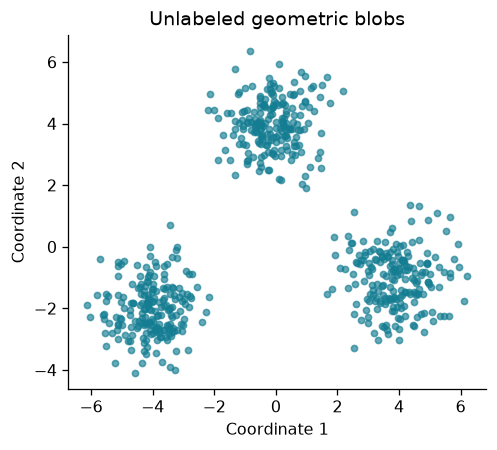

In [2]:
from sklearn.datasets import make_blobs, make_moons
X, component_for_audit = make_blobs(
    n_samples=600, centers=[[-4, -2], [0, 4], [4, -1]],
    cluster_std=0.85, random_state=SEED,
)
assert X.shape == (600, 2) and np.isfinite(X).all()
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X[:, 0], X[:, 1], s=15, color=COLORS[0], alpha=0.65)
ax.set(xlabel="Coordinate 1", ylabel="Coordinate 2", title="Unlabeled geometric blobs")
ax.set_aspect("equal")
plt.show()

## 3. Choose K from feature geometry

For each K=1,...,8, keep the lowest-inertia solution from 20 starts.
**Inertia** is the sum of squared distances to assigned centers.
**Silhouette** compares each point's average distance within its group to
its nearest other group. It is defined here for K=2,...,8; larger is better
for compact, separated groups. Select the largest mean silhouette (ties: smaller K).
An elbow is a visual aid, not a rule guaranteed to recover a true K.

,inertia,silhouette
K,,
1,11274.0262,NaN
2,4980.5089,0.5817
3,857.5144,0.7711
4,742.7444,0.6286
5,643.1426,0.4758
6,552.9106,0.3334
7,480.8598,0.3424
8,419.9094,0.3507


Selected K: 3


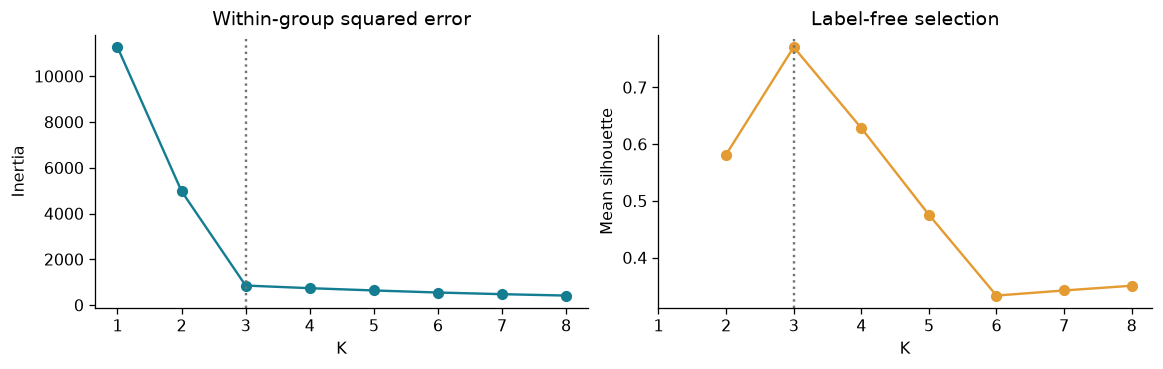

In [3]:
models = {}
rows = []
for k in range(1, 9):
    fitted = KMeans(n_clusters=k, init="k-means++", n_init=20,
                    random_state=SEED).fit(X)
    models[k] = fitted
    rows.append({"K": k, "inertia": fitted.inertia_,
                 "silhouette": silhouette_score(X, fitted.labels_) if k > 1 else np.nan})
scores = pd.DataFrame(rows).set_index("K")
selected_k = int(scores["silhouette"].idxmax())
model = models[selected_k]
labels = model.labels_
display(scores.round(4))
print("Selected K:", selected_k)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.1), constrained_layout=True)
axes[0].plot(scores.index, scores.inertia, "o-", color=COLORS[0])
axes[1].plot(scores.index, scores.silhouette, "o-", color=COLORS[1])
for ax in axes:
    ax.axvline(selected_k, color="0.45", ls=":")
    ax.set(xlabel="K", xticks=scores.index)
axes[0].set(ylabel="Inertia", title="Within-group squared error")
axes[1].set(ylabel="Mean silhouette", title="Label-free selection")
save_figure(fig, "blobs_selection")
plt.show()

## 4. Draw the assignment regions

A dense grid lets us color every location by `model.predict(grid)`.
These Voronoi regions extend beyond the observations; K-means assigns even
distant points. Centers (crosses) are means, not necessarily observed samples.
Only now compare the resulting partition with simulated component membership,
using ARI, which is unchanged when cluster IDs are renamed.

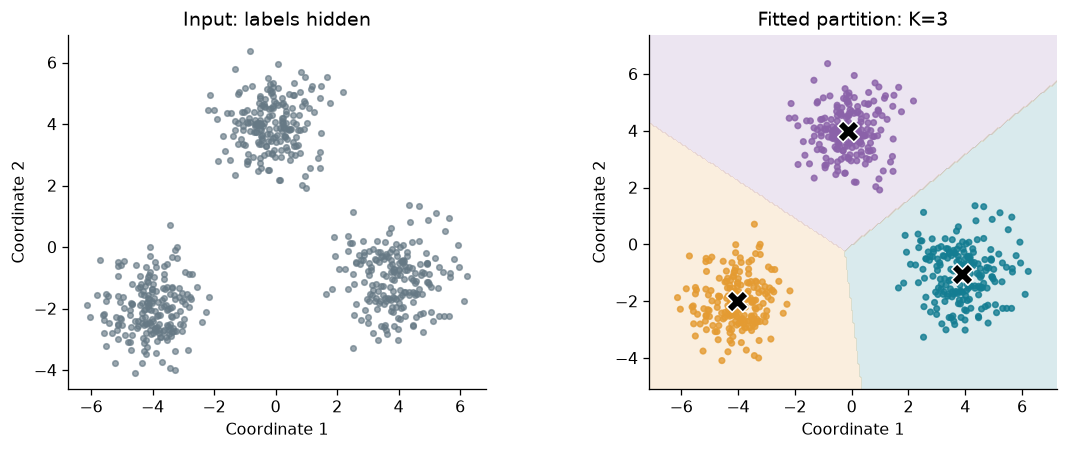

Post-selection ARI: 1.000
Cluster sizes: [200 200 200]


In [4]:
xx, yy = np.meshgrid(np.linspace(X[:, 0].min()-1, X[:, 0].max()+1, 250),
                     np.linspace(X[:, 1].min()-1, X[:, 1].max()+1, 220))
grid = np.column_stack([xx.ravel(), yy.ravel()])
regions = model.predict(grid).reshape(xx.shape)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), constrained_layout=True)
axes[0].scatter(X[:, 0], X[:, 1], s=12, color="#667985", alpha=0.65)
axes[0].set_title("Input: labels hidden")
axes[1].contourf(xx, yy, regions, levels=np.arange(selected_k+1)-0.5,
                 cmap=CMAP, vmin=0, vmax=7, alpha=0.16)
axes[1].scatter(X[:, 0], X[:, 1], c=labels, cmap=CMAP, vmin=0, vmax=7, s=12, alpha=0.8)
axes[1].scatter(*model.cluster_centers_.T, marker="X", s=180, c="black", edgecolors="white")
axes[1].set_title(f"Fitted partition: K={selected_k}")
for ax in axes:
    ax.set(xlabel="Coordinate 1", ylabel="Coordinate 2")
    ax.set_aspect("equal")
save_figure(fig, "blobs_partition")
plt.show()
blob_ari = adjusted_rand_score(component_for_audit, labels)
print(f"Post-selection ARI: {blob_ari:.3f}")
print("Cluster sizes:", np.bincount(labels))
np.testing.assert_allclose(model.predict(X), labels)
for group in range(selected_k):
    np.testing.assert_allclose(model.cluster_centers_[group], X[labels == group].mean(axis=0))

## 5. Implement Lloyd's loop with NumPy

For centers $\mu_k$, assign $z_i=\arg\min_k\|x_i-\mu_k\|^2$, then replace
each nonempty center by its assigned mean. `argmin` resolves ties by smallest ID.
Keep the previous center for an empty group (an explicit teaching policy;
library handling can differ). Each full step must not increase the objective.

This deliberately awkward initialization illustrates optimization, independently
of the multi-start model above. Compare the result with scikit-learn from the
*same* centers, with one start and a strict stopping tolerance.
Then compare its final cost with the earlier multi-start cost: monotone convergence
can still leave a poor partition.

,step,inertia
0,0,10731.857
1,1,4896.936
2,2,4892.031
3,3,4886.741
4,4,4882.818
5,5,4881.469
6,6,4880.967
7,7,4880.900
8,8,4880.880


Same-start NumPy and scikit-learn inertia: 4880.9
Earlier multi-start model inertia: 857.5


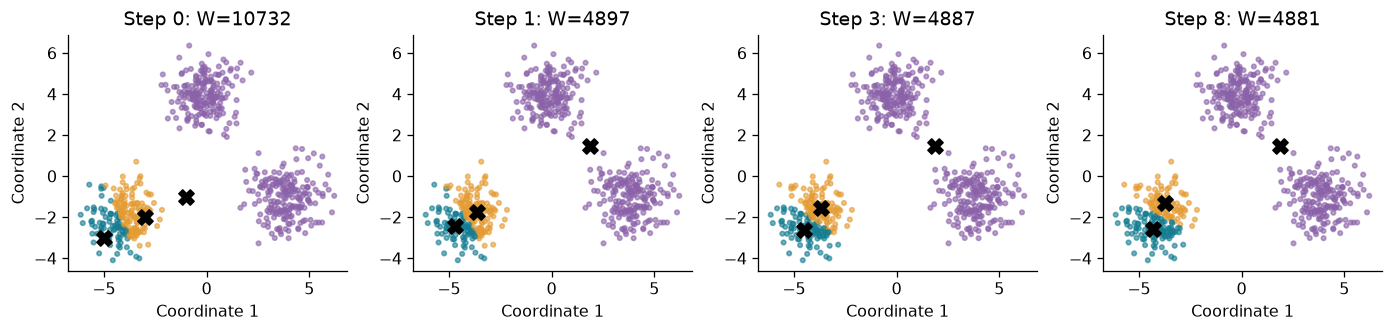

In [5]:
def lloyd_trace(points, starting_centers, max_iter=100):
    centers = np.array(starting_centers, dtype=float, copy=True)
    history = []
    for step in range(max_iter + 1):
        d2 = ((points[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        groups = d2.argmin(axis=1)
        history.append({"step": step, "centers": centers.copy(),
                        "labels": groups.copy(), "inertia": float(d2.min(axis=1).sum())})
        updated = centers.copy()
        for group in range(len(centers)):
            if np.any(groups == group):
                updated[group] = points[groups == group].mean(axis=0)
        if np.allclose(updated, centers, rtol=0, atol=1e-10):
            return history
        centers = updated
    raise RuntimeError("Lloyd loop did not converge")

initial = np.array([[-5., -3.], [-3., -2.], [-1., -1.]])
history = lloyd_trace(X, initial)
costs = np.array([state["inertia"] for state in history])
assert np.all(np.diff(costs) <= 1e-7), "The objective must not increase"
same_start = KMeans(n_clusters=3, init=initial, n_init=1, tol=1e-10,
                    algorithm="lloyd", random_state=SEED).fit(X)
np.testing.assert_allclose(costs[-1], same_start.inertia_, rtol=1e-8)
assert adjusted_rand_score(history[-1]["labels"], same_start.labels_) == 1
display(pd.DataFrame({"step": range(len(costs)), "inertia": costs}).round(3))
print(f"Same-start NumPy and scikit-learn inertia: {costs[-1]:.1f}")
print(f"Earlier multi-start model inertia: {model.inertia_:.1f}")

chosen = [0, min(1, len(history)-1), min(3, len(history)-1), len(history)-1]
fig, axes = plt.subplots(1, 4, figsize=(12, 3), constrained_layout=True)
for ax, index in zip(axes, chosen):
    state = history[index]
    ax.scatter(*X.T, c=state["labels"], cmap=CMAP, vmin=0, vmax=7, s=8, alpha=0.6)
    ax.scatter(*state["centers"].T, c="black", marker="X", s=90)
    ax.set(title=f"Step {index}: W={state['inertia']:.0f}", xlabel="Coordinate 1", ylabel="Coordinate 2")
    ax.set_aspect("equal")
save_figure(fig, "lloyd_steps")
plt.show()

## 6. Assign new points
`predict` keeps the fitted centers fixed. Distances below are Euclidean distances, not probabilities. A distant point still gets a cluster ID; a rejection rule would have to be designed separately.

In [6]:
new_points = np.array([[-4, -2], [0, 4], [4, -1], [15, 15]], dtype=float)
assigned = model.predict(new_points)
distances = model.transform(new_points)
display(pd.DataFrame({"x": new_points[:, 0], "y": new_points[:, 1],
                      "cluster": assigned, "nearest_center_distance": distances.min(axis=1)}).round(3))
np.testing.assert_array_equal(assigned, distances.argmin(axis=1))

,x,y,cluster,nearest_center_distance
0,-4.0,-2.0,1,0.048
1,0.0,4.0,2,0.128
2,4.0,-1.0,0,0.126
3,15.0,15.0,2,18.717


## 7. A geometric failure: two moons
Curved groups cannot generally be recovered by a single nearest-center region each. Fix K=2 to audit this mismatch; the simulated moon labels are used only for the final comparison.

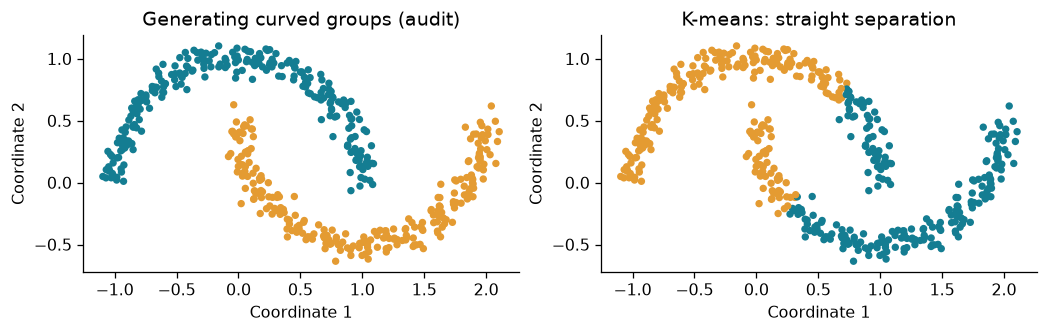

Moon ARI: 0.241


368

In [7]:
moons, moon_audit = make_moons(n_samples=500, noise=0.06, random_state=SEED)
moon_model = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit(moons)
moon_ari = adjusted_rand_score(moon_audit, moon_model.labels_)
fig, axes = plt.subplots(1, 2, figsize=(9, 3), constrained_layout=True)
for ax, colors, title in zip(axes, [moon_audit, moon_model.labels_],
                             ["Generating curved groups (audit)", "K-means: straight separation"]):
    ax.scatter(*moons.T, c=colors, cmap=CMAP, vmin=0, vmax=7, s=13)
    ax.set(title=title, xlabel="Coordinate 1", ylabel="Coordinate 2")
    ax.set_aspect("equal")
save_figure(fig, "moons_failure")
plt.show()
print(f"Moon ARI: {moon_ari:.3f}")
summary = {"selected_k": selected_k, "inertia": float(model.inertia_),
           "silhouette": float(scores.loc[selected_k, "silhouette"]),
           "ari": float(blob_ari), "moon_ari": float(moon_ari),
           "lloyd_costs": costs.tolist()}
(ROOT / ".build" / "blobs_metrics.json").write_text(json.dumps(summary, indent=2) + "\n")

## 8. Try it yourself

1. Repeat K selection with `cluster_std=1.8`, using the same centers, seed, and sample size.
   Report the selected K and silhouette, then audit ARI. Does more overlap reduce separation?
2. Multiply only coordinate 1 by 20. Compare fixed-K=3 clustering before and after
   `StandardScaler`. Why does standardizing change the question about distance?

Run the reference cells after making a prediction. These are sensitivity experiments,
not extra evidence for changing the original selected model.

In [8]:
# Reference solution 1
overlap_X, overlap_audit = make_blobs(n_samples=600,
    centers=[[-4, -2], [0, 4], [4, -1]], cluster_std=1.8, random_state=SEED)
overlap_models = {k: KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(overlap_X)
                  for k in range(2, 9)}
overlap_scores = {k: silhouette_score(overlap_X, fitted.labels_)
                  for k, fitted in overlap_models.items()}
overlap_k = max(overlap_scores, key=overlap_scores.get)
print("More overlap:", {"K": overlap_k, "silhouette": round(overlap_scores[overlap_k], 3),
                       "audit_ARI": round(adjusted_rand_score(overlap_audit, overlap_models[overlap_k].labels_), 3)})

More overlap: {'K': 3, 'silhouette': 0.534, 'audit_ARI': 0.86}


In [9]:
# Reference solution 2
from sklearn.preprocessing import StandardScaler
stretched_X = X * np.array([20.0, 1.0])
unscaled = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(stretched_X)
restored = KMeans(n_clusters=3, n_init=20, random_state=SEED).fit(
    StandardScaler().fit_transform(stretched_X))
display(pd.DataFrame({"geometry": ["stretched raw", "standardized"],
    "audit_ARI": [adjusted_rand_score(component_for_audit, unscaled.labels_),
                  adjusted_rand_score(component_for_audit, restored.labels_)]}))
# Scaling divides each squared-distance contribution by that feature's variance.

,geometry,audit_ARI
0,stretched raw,0.970251
1,standardized,1.000000


## Sources and attribution

The companion reading is GeeksforGeeks, [K means Clustering – Introduction](https://www.geeksforgeeks.org/machine-learning/k-means-clustering-introduction/)
(accessed 27 October 2026). Its two borrowed figures appear, with credits, in `k_means_clustering.pdf`.
The code, numerical experiments, and plots here were written for this teaching supplement.

Technical references: scikit-learn [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html),
[silhouette](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html),
[adjusted Rand index](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.adjusted_rand_score.html).
See [ATTRIBUTION.md](ATTRIBUTION.md) for all image URLs and dataset credits.